# Heat-bath algorithmic cooling (HBAC): a classical baseline

Heat-bath algorithmic cooling (HBAC) is the standard way to locally lower a qubit's
entropy using only a fresh, thermalized "reset" qubit and SWAP operations: repeatedly
(i) thermalize the reset qubit, (ii) apply the unitary that sorts the joint population
vector in decreasing order (approximated here by discarding coherences and sorting the
diagonal), and (iii) trace out the reset qubit. HBAC targets a *classical* (population)
notion of cooling and needs a reset qubit colder than the system.

DBAC targets something different -- suppressing *coherence* in an already-pure state --
and needs no measurements or reset qubits, only extra copies of the state itself used as
"quantum instructions" for density matrix exponentiation (see
[`dbac_main_plot.ipynb`](dbac_main_plot.ipynb)). This notebook runs HBAC on a 3-qubit
chain as a reference point for how a classical cooling baseline performs on the same
fidelity-fidelity axes used throughout this repository.

The HBAC algorithm itself lives in [`functions/hbac.py`](../functions/hbac.py); the sweep
over initial states and pure-vs-depolarized comparison lives in
[`scripts/hbac.py`](../scripts/hbac.py).

In [1]:
%matplotlib inline
import sys
sys.path.append('..')

from visualization import use_paper_style
from scripts.hbac import run_hbac_sweep
from functions.utils import apply_depolarizing_noise, fidelity_with_0, rx_sweep
import numpy as np

use_paper_style(font_size=16, figsize=(5, 3.5))

## Sweep over initial states

We sweep the initial (data-qubit) state over $R_X(\theta)|0\rangle$ for
$\theta\in[0,\pi/2]$, prepare the 3-qubit input $\rho\otimes\rho\otimes\rho$, and run
HBAC for $k=1$ and $k=6$ reset-and-compress rounds, both on the pure input and on an input
that has first been passed through a single-qubit depolarizing channel with $p=0.3$.

In [2]:
thetas = np.linspace(0, 1, 50)
psis = rx_sweep(thetas)
fidelities_initial = [fidelity_with_0(psi) for psi in psis]
mixed_states = [apply_depolarizing_noise(psi @ psi.conj().T, p=0.3) for psi in psis]

hbac_fid_pure_k1 = run_hbac_sweep(psis, step=1)
hbac_fid_mixed_k1 = run_hbac_sweep(psis, step=1, depolarizing_p=0.3)
hbac_fid_pure_k6 = run_hbac_sweep(psis, step=6)
hbac_fid_mixed_k6 = run_hbac_sweep(psis, step=6, depolarizing_p=0.3)

## Fidelity-fidelity plot

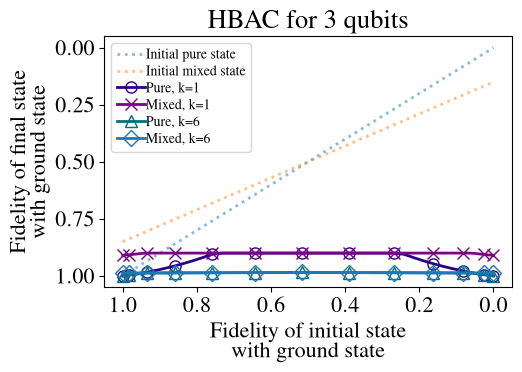

In [3]:
from visualization import plot_hbac_fidelity_fidelity

plot_hbac_fidelity_fidelity(
    fidelities_initial,
    baselines={
        "Initial pure state": fidelities_initial,
        "Initial mixed state": [fidelity_with_0(rho) for rho in mixed_states],
    },
    results={
        "Pure, k=1": hbac_fid_pure_k1,
        "Mixed, k=1": hbac_fid_mixed_k1,
        "Pure, k=6": hbac_fid_pure_k6,
        "Mixed, k=6": hbac_fid_mixed_k6,
    },
    title="HBAC for 3 qubits",
);

More rounds ($k=6$) cool the pure state further, but the depolarized input never
reaches as low an energy as the pure one -- HBAC's compression step cannot remove the
extra entropy injected by the depolarizing channel, only redistribute populations.

---
To regenerate all the figures in `plots/` from the command line instead of this notebook, run:

```bash
python scripts/hbac.py
```